# 第 2 课：频域滤波与图像增强（约 35 分钟）

目标：亲手完成低通、高通和周期噪声抑制，并理解它们在频谱上做了什么。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.grid"] = True
# 优先使用常见中文字体；最后的 DejaVu Sans 保证数字和英文正常显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def show_images(images, titles, cmap="gray"):
    """并排显示若干幅图像。"""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    axes = np.atleast_1d(axes)
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 1. 构造一幅接近工程场景的测试图

包含缓慢背景、矩形边缘、细条纹和周期噪声。


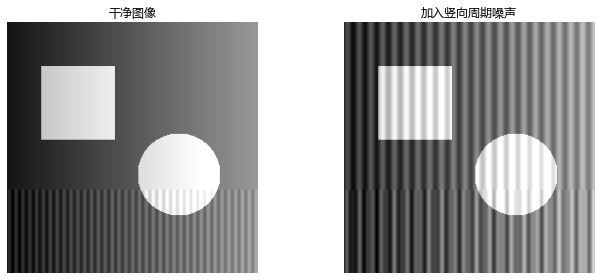

In [2]:
n = 256
y, x = np.mgrid[0:n, 0:n]

background = 0.2 + 0.45 * x / n
objects = np.zeros((n, n))
objects[45:120, 35:110] = 0.55
objects[((x - 175) ** 2 + (y - 155) ** 2) < 42 ** 2] = 0.45
fine_texture = 0.08 * np.sin(2 * np.pi * x / 7) * (y > 170)
clean = np.clip(background + objects + fine_texture, 0, 1)

periodic_noise = 0.13 * np.sin(2 * np.pi * x / 12)
noisy = np.clip(clean + periodic_noise, 0, 1)
show_images([clean, noisy], ["干净图像", "加入竖向周期噪声"])


## 2. 低通滤波：只让中心附近通过

低频位于频谱中心。圆形低通掩膜保留中心、删除外围高频，结果是平滑/模糊。


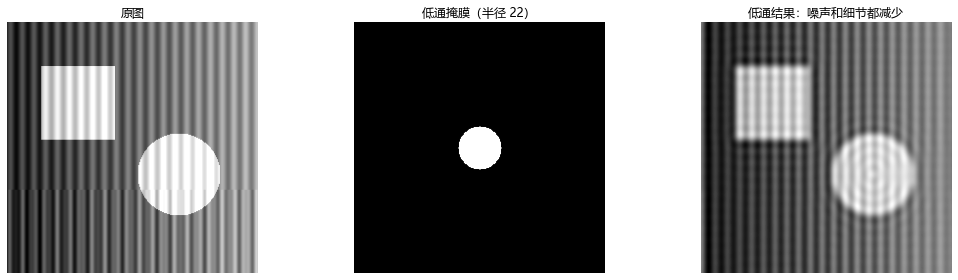

In [3]:
def frequency_grid(shape):
    h, w = shape
    yy, xx = np.mgrid[:h, :w]
    return yy - h // 2, xx - w // 2

def apply_frequency_mask(image, mask):
    F = np.fft.fftshift(np.fft.fft2(image))
    filtered_F = F * mask
    result = np.real(np.fft.ifft2(np.fft.ifftshift(filtered_F)))
    return result, F, filtered_F

dy, dx = frequency_grid(noisy.shape)
radius = np.sqrt(dx ** 2 + dy ** 2)
cutoff = 22
low_pass = radius <= cutoff

smoothed, F, low_F = apply_frequency_mask(noisy, low_pass)
show_images([noisy, low_pass, smoothed],
            ["原图", f"低通掩膜（半径 {cutoff}）", "低通结果：噪声和细节都减少"])


### 观察实验

依次把 `cutoff` 改成 8、22、60：

- 截止半径小 → 保留频率少 → 更模糊；
- 截止半径大 → 保留更多细节，也可能保留更多噪声。

这就是滤波中的核心取舍：降噪与保留细节通常不能同时最大化。


## 3. 高通滤波：保留外围

高通删除慢变化的背景，突出边缘和细纹理。它不是魔法“锐化”，而是保留快速变化。


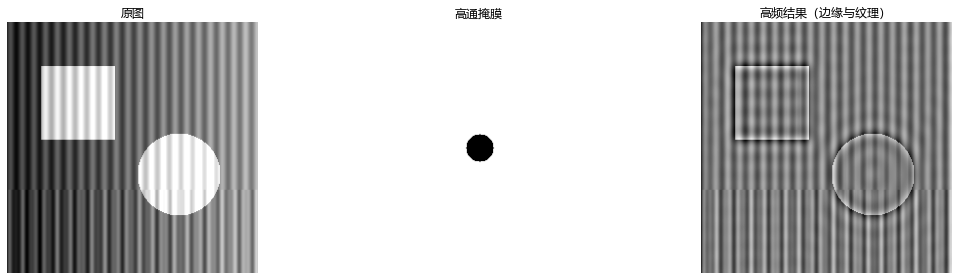

In [4]:
high_pass = radius > 14
edges, _, high_F = apply_frequency_mask(noisy, high_pass)

show_images([noisy, high_pass, edges],
            ["原图", "高通掩膜", "高频结果（边缘与纹理）"])


## 4. 工程实用招：陷波去除周期噪声

周期噪声往往在频谱中形成一对离散亮点。陷波（notch）只挖掉这对小区域，比大范围低通更能保护图像细节。


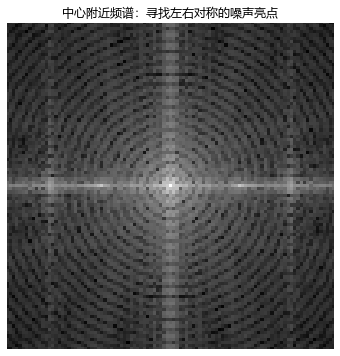

In [5]:
F_noisy = np.fft.fftshift(np.fft.fft2(noisy))
spec = np.log1p(np.abs(F_noisy))

plt.figure(figsize=(7, 6))
plt.imshow(spec)
plt.xlim(n//2 - 50, n//2 + 50)
plt.ylim(n//2 + 50, n//2 - 50)
plt.title("中心附近频谱：寻找左右对称的噪声亮点")
plt.axis("off")
plt.show()


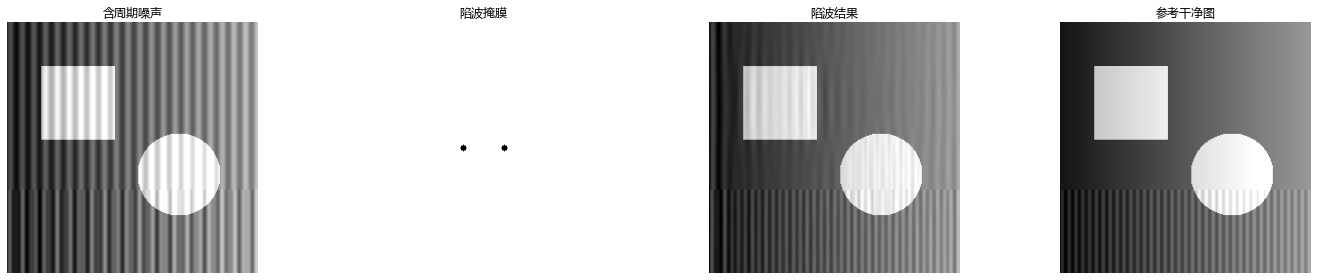

处理前平均绝对误差: 0.0787
处理后平均绝对误差: 0.0184


In [6]:
# 噪声周期约 12 像素，因此频率索引约为 n/12
offset = round(n / 12)
notch_radius = 3
notch_mask = np.ones((n, n), dtype=float)

for cx in (n // 2 - offset, n // 2 + offset):
    notch = (x - cx) ** 2 + (y - n // 2) ** 2 <= notch_radius ** 2
    notch_mask[notch] = 0

denoised, _, notched_F = apply_frequency_mask(noisy, notch_mask)
show_images([noisy, notch_mask, np.clip(denoised, 0, 1), clean],
            ["含周期噪声", "陷波掩膜", "陷波结果", "参考干净图"])

mae_before = np.mean(np.abs(noisy - clean))
mae_after = np.mean(np.abs(denoised - clean))
print(f"处理前平均绝对误差: {mae_before:.4f}")
print(f"处理后平均绝对误差: {mae_after:.4f}")


## 5. 为什么硬边界掩膜可能出现振铃？

频域突然从 1 跳到 0，相当于使用“硬截止”，图像边缘附近可能出现波纹。工程中常用高斯/巴特沃斯等平滑掩膜。


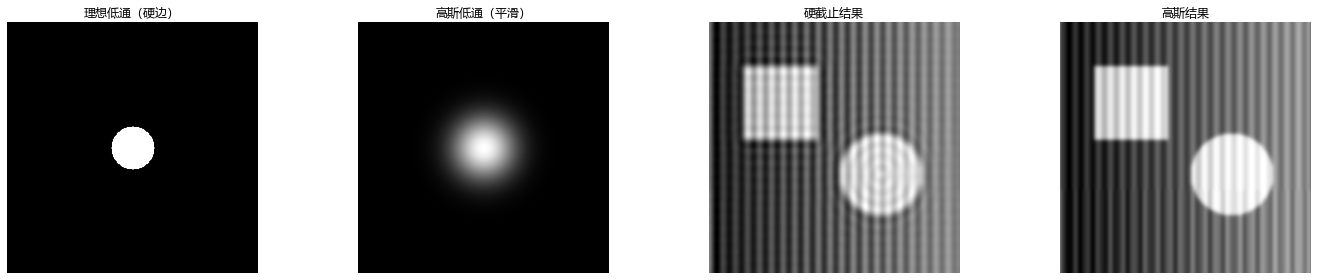

In [7]:
sigma = 22
gaussian_low_pass = np.exp(-(radius ** 2) / (2 * sigma ** 2))
gaussian_result, _, _ = apply_frequency_mask(noisy, gaussian_low_pass)

hard_result, _, _ = apply_frequency_mask(noisy, radius <= sigma)
show_images([radius <= sigma, gaussian_low_pass, hard_result, gaussian_result],
            ["理想低通（硬边）", "高斯低通（平滑）", "硬截止结果", "高斯结果"])


## 本课最小记忆卡

- 低通：模糊、降噪；
- 高通：边缘、细节；
- 陷波：精准删除周期干扰；
- 掩膜边缘越硬，越容易振铃；
- 修改频谱后必须 `ifftshift` 再 `ifft2`。
